### Planar Poiseuille Flow

We use two plates that are really wide compared to their distance between them to demonstrate fully develoepd Poiseuille flow between plates in 2D. Flow is 1 dimensional

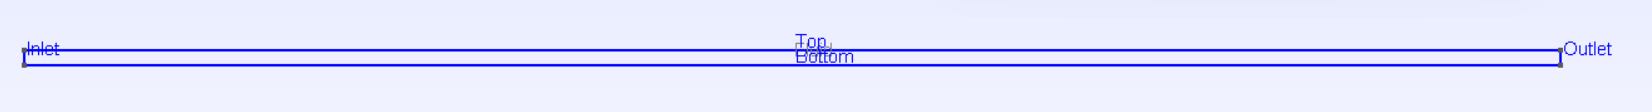

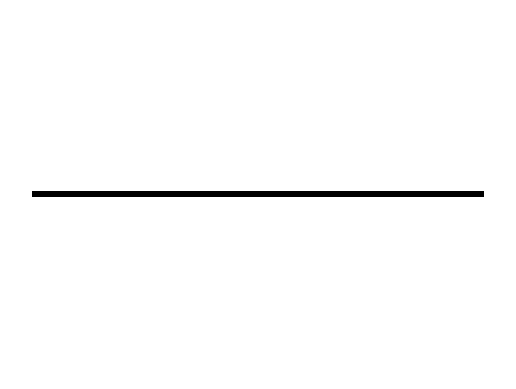

In [29]:
import meshio
from skfem import *
from skfem.helpers import dot, grad
import numpy as np

from skfem.io.meshio import from_meshio

# Add repository root to Python path. Helps to find files and modules
from pathlib import Path
import sys
sys.path.insert(0, str(Path.cwd().parent))

m = meshio.read("mesh/poiseuille_channel.msh")

mesh = from_meshio(m)

from skfem.visuals.matplotlib import draw
import matplotlib.pyplot as plt

draw(mesh)
plt.axis("equal")
plt.show()


In [46]:
from skfem import Basis, ElementTriP2

# Second order tringular elements.
e = ElementTriP2()
basis = Basis(mesh, e, intorder=4)

basis_fluid = basis.with_elements(mesh.subdomains["Fluid"])

# Dirichelt Boundaries
D_bot = basis.get_dofs(
    facets=mesh.boundaries["Bottom"]
)

D_top = basis.get_dofs(
    facets=mesh.boundaries["Top"]
)


# Test area
from skfem import Functional
@Functional
def area(w):
    return 1.0

print()
fluid_area = area.assemble(basis_fluid)
print("In units of m^2: ", fluid_area)


In units of m^2:  0.01000000000000002


We have to solve incompressible navier-stokes equation

## Incompressible Navier-Stokes Equations

### Momentum Equation

$$
\rho \left(
\frac{\partial \mathbf{u}}{\partial t}
+ (\mathbf{u}\cdot\nabla)\mathbf{u}
\right)
=
-\nabla p
+\mu\nabla^2\mathbf{u}
+\rho\mathbf{g}
$$

### Continuity Equation (Incompressibility)

$$
\nabla\cdot\mathbf{u}=0
$$

### Variables

- $\rho$: Fluid density
- $\mathbf{u}$: Velocity vector
- $t$: Time
- $p$: Pressure
- $\mu$: Dynamic viscosity
- $\mathbf{g}$: Gravitational acceleration
- $\nabla$: Gradient operator
- $\nabla^2$: Laplacian operator

We make following assumptions that lets us simplify the equation quite alot:
- steady-state and fully developed flow. This gets rid of the time derivatives
- assume gravity/hydrostatic pressure is neglegible small and/or the flow is in xy-plane. No z-direction. We get rid of the rho*g term
- We assume flow does not have y-component and it is perfectly laminar. Low Reynolds number
- no slip condition on top and bottom plates/walls.
- linear pressure gradient in x -direction. We know the pressure difference between inlet and outlet.

Equation looks like this after trimming

$$
\rho \left(
(\mathbf{u}\cdot\nabla)\mathbf{u}
\right)
=
-\nabla p
+\mu\nabla^2\mathbf{u}
$$


Lets open the left-hand-side more further


$$
\begin{aligned}
(\mathbf{u}\cdot\nabla)\mathbf{u}
&=
\begin{bmatrix}u & v\end{bmatrix}
\begin{bmatrix}
\frac{\partial}{\partial x}\\
\frac{\partial}{\partial y}
\end{bmatrix}
\begin{bmatrix}u\\v\end{bmatrix}
\\[12pt]
&=
\left(
u\frac{\partial}{\partial x}
+
v\frac{\partial}{\partial y}
\right)
\begin{bmatrix}u\\v\end{bmatrix}
\\[12pt]
&=

\begin{bmatrix}
u\frac{\partial u}{\partial x}
+
v\frac{\partial u}{\partial y}
\\[8pt]
u\frac{\partial v}{\partial x}
+
v\frac{\partial v}{\partial y}
\end{bmatrix}
\end{aligned}
$$

These partial derivatives are all zero since. y-component of flow (v) is zero like we mentioned at our assumption. Also our x-componen of flow (u) is not changing axially. Only radially. So everything goes to zero. We are left with

$$

\mu\nabla^2\mathbf{u}
=
\nabla p 
$$

and its weak form

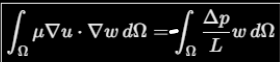

In [47]:
@BilinearForm
def laplace(u, w, r):   # test functon w  :   mu viscocity
    return r.mu*dot(grad(u), grad(w))

@LinearForm
def pressure_rhs(w, r):
    return -r.grad_p * w


# viscosity of water at 20 degrees C
mu_water = 0.3094 # Pa*s

atm = 101325.0 # Pa
p_in = 3*atm
p_out = 1*atm
dp = p_out - p_in # Pa
L = 1 # m

K = laplace.assemble(basis_fluid, mu=mu_water)
f = pressure_rhs.assemble(basis_fluid, grad_p=dp/L) 

# Boundary conditions
bot_dofs = D_bot.all()
top_dofs = D_top.all()

x = np.zeros(basis_fluid.N)

no_slip = 0.0

x[bot_dofs] = no_slip
x[top_dofs] = no_slip


D = np.concatenate([
    bot_dofs,
    top_dofs
])

K, f = enforce(K, f, D=D, x=x)

u = solve(K, f)


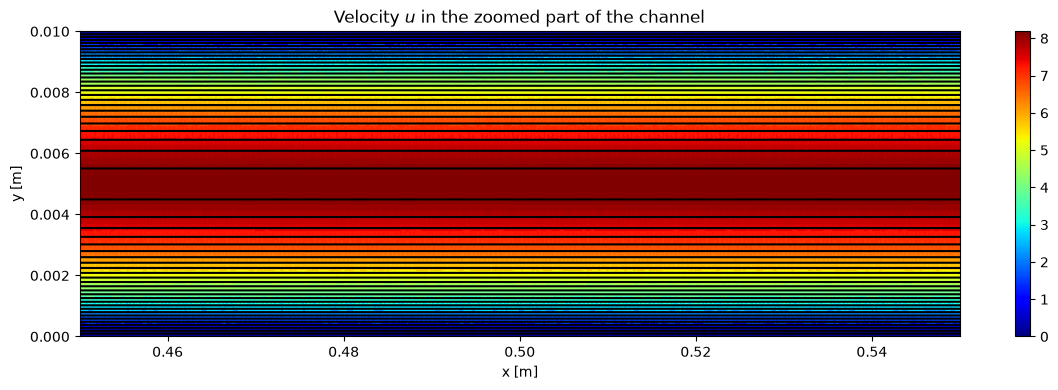

In [44]:
import matplotlib.pyplot as plt
from skfem.visuals.matplotlib import plot

fig, ax = plt.subplots(figsize=(12, 4))

plot(
    basis_fluid,
    u,
    shading="gouraud",
    colorbar=True,
    ax=ax,
)

plot(
    basis_fluid,
    u,
    ax=ax,
    levels=30,
    color="black",
    linewidths=0.4,
)

ax.set_xlim(0.45, 0.55)
ax.set_ylim(0, 0.01)
ax.set_aspect("auto")


ax.set_title(r"Velocity $u$ in the zoomed part of the channel")
ax.set_xlabel("x [m]")
ax.set_ylabel("y [m]")

plt.tight_layout()
plt.show()

Black lines are isobars of velocity

Lets evalueate the exact values for our case and compare it with or simulations.

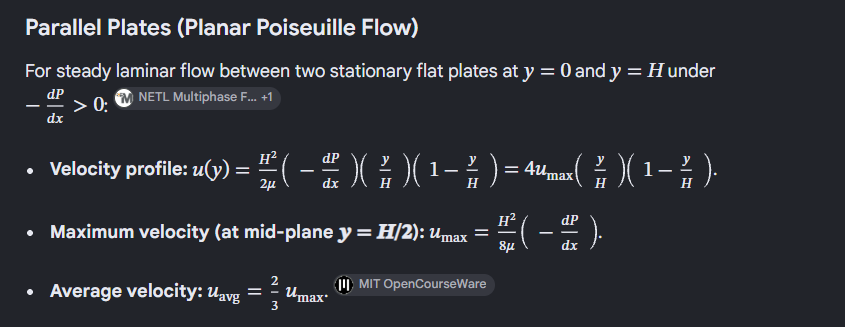

Extract values from line x=0.5m  to plot the velocity-profile

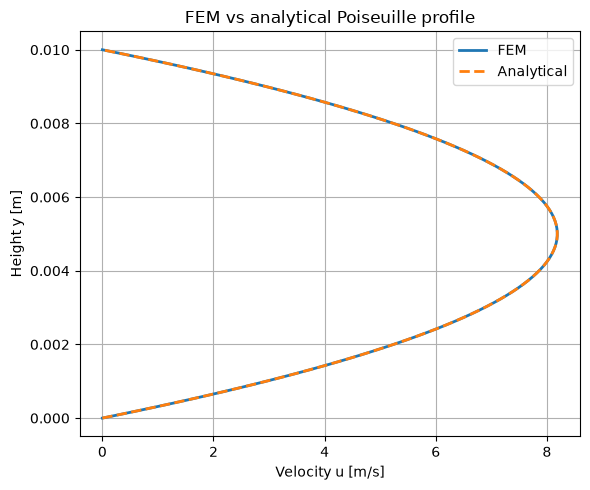

Maximum error between FEM and analytical solution:  3.375077994860476e-14


In [ ]:
# evaluate FEM solution and exact values at these points
y_values = np.linspace(0, 0.01, 100)

### EXACT
L = 1.0  # width of channel (m)
H = 0.01 # height of channel (m)

u_exact = (H**2 / (2 * mu_water )) * (-dp/L) * (y_values/H)*(1-y_values/H)


### SIMULATION

# Vertical line at the middle of the channel. Same in every x so does not matter which x we choose
x_mid = 0.5

# Coordinates must have shape (dimension, number_of_points)
points = np.vstack((
    np.full_like(y_values, x_mid),
    y_values
))


# Evaluate FEM solution at these points
u_values = basis_fluid.probes(points) @ u

plt.figure(figsize=(6, 5))

plt.plot(u_values, y_values, label="FEM", linewidth=2)
plt.plot(u_exact, y_values, "--", label="Analytical", linewidth=2)

plt.xlabel("Velocity u [m/s]")
plt.ylabel("Height y [m]")
plt.title("FEM vs analytical Poiseuille profile")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

error = np.abs(u_values - u_exact)
print("Maximum error between FEM and analytical solution: ", np.max(error))

Simulation agrees with analytical equation